In [1]:
import numpy as np
import pandas as pd
from nltk.classify import NaiveBayesClassifier
from nltk.corpus import subjectivity
from nltk.sentiment import SentimentAnalyzer
from nltk.sentiment.util import *

import numpy as np 
import pandas as pd 
#pd.set_option('display.max_colwidth', -1)
from time import time
import re
import string
import os
from pprint import pprint
import collections

import matplotlib.pyplot as plt
import seaborn as sns
sns.set(style="darkgrid")
sns.set(font_scale=1.3)

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline, FeatureUnion
from sklearn.metrics import classification_report

from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
#from sklearn.externals import joblib
import joblib as jb

#import gensim

from nltk.corpus import stopwords
from nltk.stem import PorterStemmer
from nltk.tokenize import word_tokenize

import warnings
warnings.filterwarnings('ignore')

np.random.seed(37)

# import stata_setup
# stata_setup.config('C:/Users/Farid Srouji/Stata15/', 'mp')
# import sys
# sys.path.append("C:/Users/Farid Srouji/Stata15/utilities")
# from pystata import config
# config.init()

In [2]:
# Reading the saved data pickle file
df  = pd.DataFrame()
df = pd.read_pickle('/Users/Farid Srouji/Documents/Research/VIXInterplaySentiment/master/financialmodelingprep/data/pkl/pickled_filtered_lead_para_sp500_clean_companies.pkl', compression=None)
df_sentiment=pd.read_pickle('/Users/Farid Srouji/Documents/Research/VIXInterplaySentiment/master/financialmodelingprep/data/pkl/sentiment_for_ipynb.pkl', compression=None)

In [3]:
df = df.join(df_sentiment)

In [4]:
df[["VIX"]] = df["adj close"].apply(np.int)
df["log_VIX"]=np.log(df["VIX"]/df["VIX"].shift(1))
df["sentiment_ewm"]=df["sentiment"].ewm(20).mean()

<AxesSubplot:>

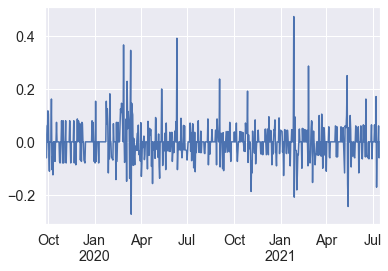

In [5]:
df["log_VIX"].plot()

In [6]:
# fig, axes = plt.subplots(10,2,figsize=(25,75))
# # for i,col in enumerate(df['VIX']):
# sns.regplot(1,'VIX',data=df, ax=axes[i,0]) # regression plot
# sns.kdeplot(df['VIX'],df['sentiment'],shade=True, ax=df[i,1]) # kernel density e

In [7]:
# # Plot each market variable with VKOSPI

# # Columns to plot 
# plot_columns = ['sentiment','VIX']

# # plot
# fig, axes = plt.subplots(10,2,figsize=(25,75))
# for i,col in enumerate(plot_columns):
#     sns.regplot(col,'VIX',data=df, ax=axes[i,0]) # regression plot
#     sns.kdeplot(df[col],df[['VIX']],shade=True, ax=axes[i,1]) # kernel density estimate plot

In [8]:
# def cor_reg_kde(x,y,data):
#     # Correlation coefficient
#     #print('correlation coefficient:',corr.loc[x,y])
    
#     # Subplot adjust
#     plt.subplots_adjust(wspace=0.5)
    
#     # Plot (regression and kernel density)
#     fig,(ax1,ax2) = plt.subplots(1,2,figsize=(10,5))
#     sns.regplot(x,y,data=data,ax=ax1)
#     sns.kdeplot(data[[x]],data[y],shade=True,ax=ax2)
    
# cor_reg_kde('pos','VIX',df)
# # cor_reg_kde('Indiv_Put_Netbuying_Quantity','Open_interest',df)
# # cor_reg_kde('Indiv_Put_Netbuying_Quantity','Indiv_Call_Netbuying_Quantity',df)
# # cor_reg_kde('Indiv_Call_Netbuying_Quantity','Open_interest',df)

In [9]:
# # Checking date for empty strings
# for date, row in df_vix.T.iteritems():
#     if type(df_vix.loc[date, 'articles']).__name__ == 'str':
#         print(date)

In [10]:
train_start_date = '2020-06-01'
train_end_date = '2021-06-24'
test_start_date = '2020-06-01'
test_end_date = '2021-06-24'

train = df.loc[train_start_date : train_end_date]
print(test_start_date)
test = df.loc[test_start_date:test_end_date]
print(test_end_date)


2020-06-01
2021-06-24


In [11]:
sentiment_score_list = []
for date, row in train.T.iteritems():
    #sentiment_score = np.asarray([df.loc[date, 'compound'],df.loc[date, 'neg'],df.loc[date, 'neu'],df.loc[date, 'pos']])
    sentiment_score = np.asarray([df.loc[date, 'neg'],df.loc[date, 'pos']])
    sentiment_score_list.append(sentiment_score)
numpy_df_train = np.asarray(sentiment_score_list)

In [12]:
sentiment_score_list = []
for date, row in test.T.iteritems():
    print(date)
    #sentiment_score = np.asarray([df.loc[date, 'compound'],df.loc[date, 'neg'],df.loc[date, 'neu'],df.loc[date, 'pos']])
    sentiment_score = np.asarray([df.loc[date, 'neg'],df.loc[date, 'pos']])
    sentiment_score_list.append(sentiment_score)
numpy_df_test = np.asarray(sentiment_score_list)

2020-06-01 00:00:00
2020-06-02 00:00:00
2020-06-03 00:00:00
2020-06-04 00:00:00
2020-06-05 00:00:00
2020-06-06 00:00:00
2020-06-07 00:00:00
2020-06-08 00:00:00
2020-06-09 00:00:00
2020-06-10 00:00:00
2020-06-11 00:00:00
2020-06-12 00:00:00
2020-06-13 00:00:00
2020-06-14 00:00:00
2020-06-15 00:00:00
2020-06-16 00:00:00
2020-06-17 00:00:00
2020-06-18 00:00:00
2020-06-19 00:00:00
2020-06-20 00:00:00
2020-06-21 00:00:00
2020-06-22 00:00:00
2020-06-23 00:00:00
2020-06-24 00:00:00
2020-06-25 00:00:00
2020-06-26 00:00:00
2020-06-27 00:00:00
2020-06-28 00:00:00
2020-06-29 00:00:00
2020-06-30 00:00:00
2020-07-01 00:00:00
2020-07-02 00:00:00
2020-07-03 00:00:00
2020-07-04 00:00:00
2020-07-05 00:00:00
2020-07-06 00:00:00
2020-07-07 00:00:00
2020-07-08 00:00:00
2020-07-09 00:00:00
2020-07-10 00:00:00
2020-07-11 00:00:00
2020-07-12 00:00:00
2020-07-13 00:00:00
2020-07-14 00:00:00
2020-07-15 00:00:00
2020-07-16 00:00:00
2020-07-17 00:00:00
2020-07-18 00:00:00
2020-07-19 00:00:00
2020-07-20 00:00:00


In [13]:
y_train = pd.DataFrame(train['sentiment'])# pd.DataFrame(train['VIX'])
y_test = pd.DataFrame(test['VIX'])

In [16]:
from treeinterpreter import treeinterpreter as ti
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import classification_report,confusion_matrix

rf = RandomForestRegressor()
print("####################### 1 ######################")
print(y_train)
print("######################## 2 #####################")
print(numpy_df_train)
y_train = np.nan_to_num(y_train)
numpy_df_train = np.nan_to_num(numpy_df_train)
pd.DataFrame(X).fillna(),
print("######################## 3 #####################")
rf.fit(numpy_df_train, y_train)

####################### 1 ######################
            sentiment
2020-06-01  86.764706
2020-06-02  82.608696
2020-06-03  86.624204
2020-06-04  85.620915
2020-06-05  50.248756
...               ...
2021-06-20      100.0
2021-06-21  92.571429
2021-06-22       80.0
2021-06-23  91.812865
2021-06-24  89.010989

[389 rows x 1 columns]
######################## 2 #####################
[[0.018 0.118]
 [0.024 0.114]
 [0.021 0.136]
 [0.022 0.131]
 [0.1   0.101]
 [0.    0.   ]
 [0.    0.284]
 [0.082 0.111]
 [0.041 0.11 ]
 [0.01  0.115]
 [0.045 0.166]
 [0.017 0.139]
 [0.031 0.177]
 [0.1   0.165]
 [0.014 0.09 ]
 [0.027 0.139]
 [0.04  0.146]
 [0.033 0.135]
 [0.03  0.072]
 [0.    0.   ]
 [0.    0.   ]
 [0.025 0.13 ]
 [0.006 0.138]
 [0.023 0.193]
 [0.032 0.136]
 [0.029 0.074]
 [0.    0.   ]
 [0.    0.   ]
 [0.066 0.108]
 [0.039 0.144]
 [0.026 0.142]
 [0.05  0.119]
 [0.    0.089]
 [0.09  0.156]
 [0.04  0.257]
 [0.05  0.111]
 [0.031 0.095]
 [0.021 0.158]
 [0.062 0.109]
 [0.117 0.088]
 [0.    0.   ]

ValueError: Input contains NaN

In [ ]:
# Time series data source: fpp pacakge in R.
import matplotlib.pyplot as plt
df = pd.read_csv('https://raw.githubusercontent.com/selva86/datasets/master/a10.csv', parse_dates=['date'], index_col='date')

# Draw Plot
def plot_df(df, x, y, title="", xlabel='Date', ylabel='Value', dpi=100):
    plt.figure(figsize=(16,5), dpi=dpi)
    plt.plot(x, y, color='tab:red')
    plt.gca().set(title=title, xlabel=xlabel, ylabel=ylabel)
    plt.show()

plot_df(df, x=df.index, y=df.value, title='Monthly anti-diabetic drug sales in Australia from 1992 to 2008.')    

In [ ]:
# Import Data
df = pd.read_csv('https://raw.githubusercontent.com/selva86/datasets/master/a10.csv', parse_dates=['date'], index_col='date')
df.reset_index(inplace=True)

# Prepare data
df['year'] = [d.year for d in df.date]
df['month'] = [d.strftime('%b') for d in df.date]
years = df['year'].unique()

# Draw Plot
fig, axes = plt.subplots(1, 2, figsize=(20,7), dpi= 80)
sns.boxplot(x='year', y='value', data=df, ax=axes[0])
sns.boxplot(x='month', y='value', data=df.loc[~df.year.isin([1991, 2008]), :])

# Set Title
axes[0].set_title('Year-wise Box Plot\n(The Trend)', fontsize=18); 
axes[1].set_title('Month-wise Box Plot\n(The Seasonality)', fontsize=18)
plt.show()

In [ ]:
print(rf.feature_importances_)

In [ ]:
prediction, bias, contributions = ti.predict(rf, numpy_df_test)

In [ ]:
prediction

In [ ]:
contributions

In [ ]:
import matplotlib.pyplot as plt
%matplotlib inline

In [ ]:
print(test_start_date)

idx = pd.date_range(test_start_date, test_end_date)
print(test_end_date)
predictions_df = pd.DataFrame(data=prediction[0:], index = idx, columns=['VIX'] )

In [ ]:
predictions_df

In [ ]:
#predictions_df.plot() 
#test['VIX'].plot()

predictions_plot = predictions_df.plot()

fig = y_test.plot(ax = predictions_plot).get_figure()
fig.savefig("/Users/Farid Srouji/Documents/Research/VIX prediction/master/financialmodelingprep/images/random_forest_without_smoothing_sp500.png")
#matplotlib.pyplot.savefig("C:\Users\Farid\Documents\Project Options predictions\graphs\random forest without smoothing.png")

In [ ]:
ax = predictions_df.rename(columns={"VIX": "predicted_VIX"}).plot(title='Random Forest predicted VIX 1 year')
ax.set_xlabel("Dates")
ax.set_ylabel("VIX")
fig = y_test.rename(columns={"VIX": "actual_VIX"}).plot(ax = ax).get_figure()
fig.savefig("/Users/Farid Srouji/Documents/Research/VIX prediction/master/financialmodelingprep/images/random_forest_without_smoothing2_sp500.png")

# colors = ['332288', '88CCEE', '44AA99', '117733', '999933', 'DDCC77', 'CC6677', '882255', 'AA4499']

In [ ]:
test

In [ ]:
# Increasing the VIX by a constant value so that it represents closing VIX during the testing

In [ ]:
from datetime import datetime, timedelta

temp_date = test_start_date
print(test_start_date)
print(datetime.astimezone)
average_last_5_days_test = 0
total_days = 10
for i in range(total_days):
    average_last_5_days_test += test.loc[temp_date, 'VIX']
    # Converting string to date time
    temp_date = datetime.strptime(temp_date, "%Y-%m-%d").date()
    # Reducing one day from date time
    difference = temp_date + timedelta(days=1)
    # Converting again date time to string
    temp_date = difference.strftime('%Y-%m-%d')
    #print temp_date
average_last_5_days_test = average_last_5_days_test / total_days
print (average_last_5_days_test)

temp_date = test_start_date
average_upcoming_5_days_predicted = 0
for i in range(total_days):
    average_upcoming_5_days_predicted += predictions_df.loc[temp_date, 'VIX']
    # Converting string to date time
    temp_date = datetime.strptime(temp_date, "%Y-%m-%d").date()
    # Adding one day from date time
    difference = temp_date + timedelta(days=1)
    # Converting again date time to string
    temp_date = difference.strftime('%Y-%m-%d')
    print(temp_date)
average_upcoming_5_days_predicted = average_upcoming_5_days_predicted / total_days
print (average_upcoming_5_days_predicted)
#average train.loc['2013-12-31', 'VIX'] - advpredictions_df.loc['2014-01-01', 'VIX']
difference_test_predicted_VIX = average_last_5_days_test - average_upcoming_5_days_predicted
print (difference_test_predicted_VIX)

In [ ]:
predictions_df

In [ ]:
# Adding 6177 to all the advpredictions_df VIX values
predictions_df['VIX'] = predictions_df['VIX'] + difference_test_predicted_VIX
predictions_df

In [ ]:
ax = predictions_df.rename(columns={"VIX": "predicted_VIX"}).plot(title='Random Forest predicted VIX 1 year after aligning')
ax.set_xlabel("Dates")
ax.set_ylabel("Options Volatility")
fig = y_test.rename(columns={"VIX": "actual_VIX"}).plot(ax = ax).get_figure()
fig.savefig("/Users/Farid Srouji/Documents/Research/VIX prediction/master/financialmodelingprep/images/random_forest_with_aligning_sp500.png")



# Smoothing the time series data

# Applying EWM pandas to smooth the VIX volatility

In [ ]:
predictions_df

In [ ]:
predictions_df['ewm'] = predictions_df["VIX"].ewm(span=60).mean()

In [ ]:
predictions_df

In [ ]:
predictions_df['actual_value'] = test['VIX']
predictions_df['actual_value_ewm'] = predictions_df["actual_value"].ewm(span=60).mean()

In [ ]:
predictions_df

In [ ]:
# Changing column names
predictions_df.columns = ['predicted_VIX', 'average_predicted_VIX', 'actual_VIX', 'average_actual_VIX']

In [ ]:
# Now plotting test predictions after smoothing
predictions_plot = predictions_df.plot(title='Random Forest predicted VIX 1 year after aligning & smoothing')
predictions_plot.set_xlabel("Dates")
predictions_plot.set_ylabel("VIX")
fig = predictions_plot.get_figure()
fig.savefig("/Users/Farid Srouji/Documents/Research/VIX prediction/master/financialmodelingprep/images/random_forest_after_smoothing_var_sp500.png")


In [ ]:
# Plotting just predict and actual average curves
predictions_df_average = predictions_df[['average_predicted_VIX', 'average_actual_VIX']]
predictions_plot = predictions_df_average.plot(title='Random Forest 1 years after aligning & smoothing')
predictions_plot.set_xlabel("Dates")
predictions_plot.set_ylabel("VIX")
fig = predictions_plot.get_figure()
fig.savefig("/Users/Farid Srouji/Documents/Research/VIX prediction/master/financialmodelingprep/images/random_forest_after_smoothing2_mean_sp500.png")

In [ ]:
# Increasing the VIX by a constant value so that it represents closing VIX during the testing

In [ ]:
def offset_value(test_start_date, test, predictions_df):
    temp_date = test_start_date
    average_last_5_days_test = 0
    average_upcoming_5_days_predicted = 0
    total_days = 10
    for i in range(total_days):
        average_last_5_days_test += test.loc[temp_date, 'VIX']
        temp_date = datetime.strptime(temp_date, "%Y-%m-%d").date()
        difference = temp_date + timedelta(days=1)
        temp_date = difference.strftime('%Y-%m-%d')
    average_last_5_days_test = average_last_5_days_test / total_days

    temp_date = test_start_date
    for i in range(total_days):
        average_upcoming_5_days_predicted += predictions_df.loc[temp_date, 'VIX']
        temp_date = datetime.strptime(temp_date, "%Y-%m-%d").date()
        difference = temp_date + timedelta(days=1)
        temp_date = difference.strftime('%Y-%m-%d')
    average_upcoming_5_days_predicted = average_upcoming_5_days_predicted / total_days
    difference_test_predicted_VIX = average_last_5_days_test - average_upcoming_5_days_predicted
    return difference_test_predicted_VIX

# LogisticRegression

In [ ]:
from treeinterpreter import treeinterpreter as ti
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LogisticRegression
from datetime import datetime, timedelta

# average_upcoming_5_days_predicted += predictions_df.loc[temp_date, 'VIX']
# # Converting string to date time
# temp_date = datetime.strptime(temp_date, "%Y-%m-%d").date()
# # Adding one day from date time
# difference = temp_date + timedelta(days=1)
# # Converting again date time to string
# temp_date = difference.strftime('%Y-%m-%d')
        
# start_year = datetime.strptime(train_start_date, "%Y-%m-%d").date().month

prediction_list = []

# Splitting the training and testing data
train_start_date = '2019-09-25'
train_end_date = '2021-06-24'
test_start_date = '2019-09-25'
test_end_date = '2021-06-24'
train = df.loc[train_start_date : train_end_date]
test = df.loc[test_start_date : test_end_date]

# Calculating the sentiment score
sentiment_score_list = []
for date, row in train.T.iteritems():
    sentiment_score = np.asarray([df.loc[date, 'compound'],df.loc[date, 'neg'],df.loc[date, 'neu'],df.loc[date, 'pos']])
    #sentiment_score = np.asarray([df.loc[date, 'neg'],df.loc[date, 'pos']])
    sentiment_score_list.append(sentiment_score)
numpy_df_train = np.asarray(sentiment_score_list)
sentiment_score_list = []
print("#1")
for date, row in test.T.iteritems():
    sentiment_score = np.asarray([df.loc[date, 'compound'],df.loc[date, 'neg'],df.loc[date, 'neu'],df.loc[date, 'pos']])
    #sentiment_score = np.asarray([df.loc[date, 'neg'],df.loc[date, 'pos']])
    sentiment_score_list.append(sentiment_score)
numpy_df_test = np.asarray(sentiment_score_list)
# Generating models
# Linear regression model
lr = LogisticRegression()
print(sys.getsizeof(numpy_df_train))
print(sys.getsizeof(train['VIX']))

print("####################### 1 ######################")
print(train['VIX'])
print("######################## 2 #####################")
print(numpy_df_train)
print("######################## 3 #####################")
lr.fit(numpy_df_train, train['VIX'])

#   if len(np.sum(train['VIX'])) in [len(train['VIX']),0]:
#       print ("all one class")
#       #do something else
#   else:
#       #OK to proceed
#       lenreg.fit(numpy_df_train, train['VIX'])
#       y_pred = lenreg.predict(numpy_df_train)
#       print (metics.accuracy_score(y_test, y_pred))


print("#6")

prediction = lr.predict(numpy_df_test)
prediction_list.append(prediction)
print (train_start_date + ' ' + train_end_date + ' ' + test_start_date + ' ' + test_end_date)
idx = pd.date_range(test_start_date, test_end_date)
#print year
predictions_df_list = pd.DataFrame(data=prediction[0:], index = idx, columns=['VIX'])

difference_test_predicted_VIX = offset_value(test_start_date, test, predictions_df_list)
# Adding offset to all the advpredictions_df VIX values
predictions_df_list['VIX'] = predictions_df_list['VIX'] + difference_test_predicted_VIX
predictions_df_list

# Smoothing the plot
predictions_df_list['ewm'] = predictions_df_list["VIX"].ewm(span=10).mean()
predictions_df_list['actual_value'] = test['VIX']
predictions_df_list['actual_value_ewm'] = predictions_df_list["actual_value"].ewm(span=10).mean()
# Changing column names
predictions_df_list.columns = ['predicted_VIX', 'average_predicted_VIX', 'actual_VIX', 'average_actual_VIX']
predictions_df_list.plot()
predictions_df_list_average = predictions_df_list[['average_predicted_VIX', 'average_actual_VIX']]
predictions_df_list_average.plot()
print("#7")
#     predictions_df_list.show()


In [ ]:
# #TEMP
# # Columns to plot 
# plot_columns = ['sentiment','VIX']

# # plot
# fig, axes = plt.subplots(10,2,figsize=(25,75))
# for i,col in enumerate(plot_columns):
#     sns.regplot(col,'VIX',data=train, ax=axes[i,0]) # regression plot
#     sns.kdeplot(train[col],train['VIX'],shade=True, ax=axes[i,1]) # kernel density estimate plot
  

In [ ]:
lr.classes_

In [ ]:
lr.coef_[0]

# RandomForestRegressor

In [ ]:
from treeinterpreter import treeinterpreter as ti
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LogisticRegression
from datetime import datetime, timedelta

# average_upcoming_5_days_predicted += predictions_df.loc[temp_date, 'VIX']
# # Converting string to date time
# temp_date = datetime.strptime(temp_date, "%Y-%m-%d").date()
# # Adding one day from date time
# difference = temp_date + timedelta(days=1)
# # Converting again date time to string
# temp_date = difference.strftime('%Y-%m-%d')
        
# start_year = datetime.strptime(train_start_date, "%Y-%m-%d").date().month

prediction_list = []
# Splitting the training and testing data
train_start_date = '2019-09-25'
train_end_date = '2021-06-24'
test_start_date = '2019-09-25'
test_end_date = '2021-06-24'
train = df.loc[train_start_date : train_end_date]
test = df.loc[test_start_date:test_end_date]

# Calculating the sentiment score
sentiment_score_list = []
for date, row in train.T.iteritems():
    sentiment_score = np.asarray([df.loc[date, 'compound'],df.loc[date, 'neg'],df.loc[date, 'neu'],df.loc[date, 'pos']])
    #sentiment_score = np.asarray([df.loc[date, 'neg'],df.loc[date, 'pos']])
    sentiment_score_list.append(sentiment_score)
numpy_df_train = np.asarray(sentiment_score_list)
sentiment_score_list = []
for date, row in test.T.iteritems():
    sentiment_score = np.asarray([df.loc[date, 'compound'],df.loc[date, 'neg'],df.loc[date, 'neu'],df.loc[date, 'pos']])
    #sentiment_score = np.asarray([df.loc[date, 'neg'],df.loc[date, 'pos']])
    sentiment_score_list.append(sentiment_score)
numpy_df_test = np.asarray(sentiment_score_list)
# Generating models
rf = RandomForestRegressor(random_state=0)
rf.fit(numpy_df_train, train['VIX'])
#print rf

prediction, bias, contributions = ti.predict(rf, numpy_df_test)
prediction_list.append(prediction)
#print train_start_date + ' ' + train_end_date + ' ' + test_start_date + ' ' + test_end_date
idx = pd.date_range(test_start_date, test_end_date)
#print year
predictions_df_list = pd.DataFrame(data=prediction[0:], index = idx, columns=['VIX'])

difference_test_predicted_VIX = offset_value(test_start_date, test, predictions_df_list)
# Adding offset to all the advpredictions_df VIX values
predictions_df_list['VIX'] = predictions_df_list['VIX'] + difference_test_predicted_VIX
predictions_df_list

# Smoothing the plot
predictions_df_list['ewm'] = predictions_df_list["VIX"].ewm(span=60).mean()
predictions_df_list['actual_value'] = test['VIX']
predictions_df_list['actual_value_ewm'] = predictions_df_list["actual_value"].ewm(span=10).mean()
# Changing column names
predictions_df_list.columns = ['predicted_VIX', 'average_predicted_VIX', 'actual_VIX', 'average_actual_VIX']
predictions_df_list.plot()
predictions_df_list_average = predictions_df_list[['average_predicted_VIX', 'average_actual_VIX']]
predictions_df_list_average.plot()

#     predictions_df_list.show()


In [ ]:
# from IPython.display import Image  
# dot_data = tree.export_graphviz(rf, out_file=None, 
#                      feature_names=['comp', 'neg', 'neu', 'pos'],  
#                      class_names=iris.target_names,  
#                      filled=True, rounded=True,  
#                      special_characters=True)  
# graph = pydotplus.graph_from_dot_data(dot_data)  
# Image(graph.create_png())

# MLP Classifier

In [ ]:
from sklearn.neural_network import MLPClassifier
from datetime import datetime, timedelta

# average_upcoming_5_days_predicted += predictions_df.loc[temp_date, 'VIX']
# # Converting string to date time
# temp_date = datetime.strptime(temp_date, "%Y-%m-%d").date()
# # Adding one day from date time
# difference = temp_date + timedelta(days=1)
# # Converting again date time to string
# temp_date = difference.strftime('%Y-%m-%d')
        
# start_year = datetime.strptime(train_start_date, "%Y-%m-%d").date().month

prediction_list = []
# Splitting the training and testing data
train_start_date = '2019-09-25'
train_end_date = '2021-06-24'
test_start_date = '2019-09-25'
test_end_date = '2021-06-24'
train = df.loc[train_start_date : train_end_date]
test = df.loc[test_start_date:test_end_date]

# Calculating the sentiment score
sentiment_score_list = []
for date, row in train.T.iteritems():
    sentiment_score = np.asarray([df.loc[date, 'compound'],df.loc[date, 'neg'],df.loc[date, 'neu'],df.loc[date, 'pos']])
    #sentiment_score = np.asarray([df.loc[date, 'neg'],df.loc[date, 'pos']])
    sentiment_score_list.append(sentiment_score)
numpy_df_train = np.asarray(sentiment_score_list)
sentiment_score_list = []
for date, row in test.T.iteritems():
    sentiment_score = np.asarray([df.loc[date, 'compound'],df.loc[date, 'neg'],df.loc[date, 'neu'],df.loc[date, 'pos']])
    #sentiment_score = np.asarray([df.loc[date, 'neg'],df.loc[date, 'pos']])
    sentiment_score_list.append(sentiment_score)
numpy_df_test = np.asarray(sentiment_score_list)

# Generating models
mlpc = MLPClassifier(hidden_layer_sizes=(100, 200, 100), activation='relu', 
                        solver='lbfgs', alpha=0.005, learning_rate_init = 0.001, shuffle=False) # span = 20 # best 1
mlpc.fit(numpy_df_train, train['VIX'])   
prediction = mlpc.predict(numpy_df_test)

prediction_list.append(prediction)
#print train_start_date + ' ' + train_end_date + ' ' + test_start_date + ' ' + test_end_date
idx = pd.date_range(test_start_date, test_end_date)
#print year
predictions_df_list = pd.DataFrame(data=prediction[0:], index = idx, columns=['VIX'])

difference_test_predicted_VIX = offset_value(test_start_date, test, predictions_df_list)
# Adding offset to all the advpredictions_df VIX values
predictions_df_list['VIX'] = predictions_df_list['VIX'] + difference_test_predicted_VIX
predictions_df_list

# Smoothing the plot
predictions_df_list['ewm'] = predictions_df_list["VIX"].ewm(span=20).mean()
predictions_df_list['actual_value'] = test['VIX']
predictions_df_list['actual_value_ewm'] = predictions_df_list["actual_value"].ewm(span=20).mean()
# Changing column names
predictions_df_list.columns = ['predicted_VIX', 'average_predicted_VIX', 'actual_VIX', 'average_actual_VIX']
predictions_df_list.plot()
predictions_df_list_average = predictions_df_list[['average_predicted_VIX', 'average_actual_VIX']]
predictions_df_list_average.plot()

#     predictions_df_list.show()
    

In [ ]:

#my addition
# import matplotlib.pyplot as plt
# from sklearn.datasets import make_blobs

# n_samples = 200
# blob_centers = ([1, 1], [3, 4], [1, 3.3], [3.5, 1.8])
# data, labels = make_blobs(n_samples=n_samples, 
#                           centers=blob_centers, 
#                           cluster_std=0.5,
#                           random_state=0)


# colours = ('green', 'orange', "blue", "magenta")
# fig, ax = plt.subplots()

# for n_class in range(len(blob_centers)):
#     ax.scatter(data[labels==n_class][:, 0], 
#                data[labels==n_class][:, 1], 
#                c=colours[n_class], 
#                s=30, 
#                label=str(n_class))

In [ ]:
mlpc = MLPClassifier(hidden_layer_sizes=(100, 200, 100), activation='tanh', 
                         solver='lbfgs', alpha=0.010, learning_rate_init = 0.001, shuffle=False)
mlpc = MLPClassifier(hidden_layer_sizes=(100, 200, 100), activation='relu', 
                         solver='lbfgs', alpha=0.010, learning_rate_init = 0.001, shuffle=False) # span = 20
mlpc = MLPClassifier(hidden_layer_sizes=(100, 200, 100), activation='relu', 
                         solver='lbfgs', alpha=0.005, learning_rate_init = 0.001, shuffle=False) # span = 20 # best 1
mlpc = MLPClassifier(hidden_layer_sizes=(100, 200, 50), activation='relu', 
                         solver='lbfgs', alpha=0.005, learning_rate_init = 0.001, shuffle=False)
                     

In [ ]:
# checking the performance of training data itself
prediction, bias, contributions = ti.predict(rf, numpy_df_train)
idx = pd.date_range(train_start_date, train_end_date)
predictions_df1 = pd.DataFrame(data=prediction[0:], index = idx, columns=['VIX'])
predictions_df1.plot()
train['VIX'].plot()